<table style="width: 100%; border: none; background: #f8f9fa; padding: 20px; border-radius: 10px;">
    <tr>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://www.inf.ucv.cl/wp-content/uploads/2020/05/logo_escuela.jpg" width="170">
        </td>
        <td style="width: 56%; border: none; vertical-align: middle; text-align: center; padding: 0 20px;">
            <h1 style="font-size: 28px; color: #1a3b5c; margin-bottom: 16px; border-bottom: 2px solid #1a3b5c; padding-bottom: 8px;">Tarea 2: Clasificacion, Costos Asimetricos y Arboles</h1>
            <p style="font-size: 16px; margin: 8px 0;"><strong>Pontificia Universidad Catolica de Valparaiso</strong><br>
            <strong>Escuela de Ingenieria Informatica</strong></p>
            <p style="font-size: 14px; color: #333; margin: 12px 0;"><strong>OII432 Machine Learning</strong><br>
            <strong>Semestre: 2-2026</strong><br>
            <strong>Profesor: Carlos Valle</strong></p>
        </td>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://upload.wikimedia.org/wikipedia/commons/c/cb/PUCV_Escudo2016.svg" width="110">
        </td>
    </tr>
</table>

# Pregunta 2: desafío Kaggle
Integrantes:
- Nelson Fuentes
- Eduardo Pérez
- Eduardo Sandoval
- Ricardo Pastén

Se predice si una licitación quedará desierta con información disponible al publicarla. La pauta adjunta confirma que la métrica es F1 para la clase desierta.


El trabajo cubre el año calendario completo, del **1 de enero al 31 de diciembre de 2024**, en cuatro bloques uniformes de tres meses. Se organiza en datos, construcción de variables, protocolo temporal, comparación con validación cruzada y ensamblajes, umbral y evaluación, y ajuste final.

Se comparan regresiones logísticas, árbol, Random Forest, boosting y XGBoost, además de seis ensamblajes de votación suave. El preprocesamiento se aprende dentro de cada entrenamiento. El texto usa TF-IDF, las categorías one-hot y los montos se expresan en CLP.

La validación cruzada es temporal y expansiva: T1 → T2 y T1+T2 → T3. T4 queda reservado para una evaluación temporal reservada. Se elige la configuración por AP media entre folds y se fija el umbral F1 con probabilidades fuera de muestra de T2 y T3.

Para aproximar cuándo se conoce una etiqueta se utiliza cierre + 30 días. Solo entran al entrenamiento las etiquetas disponibles en su fecha de corte; para decidir antes de T4, las etiquetas de validación deben estar disponibles antes del 1 de octubre. La evaluación retrospectiva de T4 usa todos sus desenlaces proporcionados, incluidos los de diciembre, sin utilizarlos para cambiar la elección. El ajuste final respeta la disponibilidad antes de la primera publicación de prueba.


## Librerías


In [ ]:
import hashlib
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from scipy.special import expit
from scipy.sparse import csr_matrix, hstack

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGET = "y_desierta"
plt.rcParams["figure.figsize"] = (12, 5)
sns.set_palette("deep")
print(f"NumPy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

NumPy 1.26.2 | pandas 2.3.3 | scikit-learn 1.9.1


# 1. Datos y protocolo

Se predice `y_desierta`: **1** significa que la licitación quedó desierta y **0**, que no quedó desierta. Primero se revisan los archivos, los datos faltantes y la distribución de ambas clases. Después se separan los datos por fecha y se fija cuánto pesa cada tipo de error.


### Carga de datos

In [221]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
assert list(pd.read_csv("sample_submission.csv", nrows=0).columns) == ["id", TARGET]
# Solo se leen los identificadores de la plantilla; sus etiquetas de ejemplo se ignoran.
sample_submission_df = pd.read_csv("sample_submission.csv", usecols=["id"])

### Inspección e integridad

In [222]:
for nombre, df in {"train": train_df, "test": test_df}.items():
    print(nombre, df.shape)
    display(df.head(3))

train (152553, 24)


,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion,y_desierta
0,248328745624,2024-03-25T15:32:20Z,LP04-2024 AV. UNO SUR AYSEN,"CONSTRUCCIÓN CALZADA H.C.V. AVENIDA UNO SUR, P...",NaN,NaN,open,Licitación Pública MOP (O1),1,1.0,...,2024-04-12T10:00:00Z,17.769,False,11.0,SERVICIO DE VIVIENDA Y URBANIZACION XI REGION ...,CL-MP-1653,618230007,Región Aysén del General Carlos Ibáñez del Campo,RAMON FREIRE Nº 5,0
1,760555527084,2024-03-21T14:29:28Z,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...,licitar las obras de infraestructura de mejora...,NaN,NaN,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),1,1.0,...,2024-04-15T20:00:00Z,25.230,False,21.0,CORPORACION MUNICIPAL DE EDUCACION Y SALUD DE ...,CL-MP-1274286,709255002,Región Metropolitana de Santiago,O'HIGGINS 840,1
2,224829110991,2024-01-26T12:37:41Z,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA USUA...,3500000.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),55,12150.0,...,2024-02-01T13:24:00Z,6.032,False,3.0,I MUNICIPALIDAD DE CHANCO | I MUNICIPALIDAD DE...,CL-MP-4391,69120300K,Región del Maule,Ignacio Carrera Pinto Nº 31,0


test (21829, 23)


,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_inicio,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion
0,47254358932,2025-03-12T15:46:53Z,SC 36914 (CM) ADQUISICIÓN DE MOBILIARIO PARA C...,ADQUISICIÓN DE MOBILIARIO PARA CLÍNICA JURÍDIC...,4999999.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),3,24.0,...,2025-03-12T15:46:47Z,2025-03-20T15:30:00Z,7.988,False,2.0,UNIVERSIDAD DE PLAYA ANCHA DE CIENCIAS DE LA E...,CL-MP-5385,707547006,Región Metropolitana de Santiago,Av. A Bello 2687
1,295671198916,2025-01-06T17:34:25Z,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,20000000.0,CLP,open,Licitación Pública Entre 100 y 1000 UTM (LE),45,123593.0,...,2025-01-06T17:34:19Z,2025-01-16T19:53:00Z,10.096,False,3.0,I MUNICIPALIDAD DE MAULE | I MUNICIPALIDAD DE ...,CL-MP-5605,691109003,Región del Maule,Balmaceda N° 350
2,214756376398,2025-02-26T12:48:51Z,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,NaN,NaN,open,Licitación Pública Entre 100 y 1000 UTM (LE),1,19000.0,...,2025-02-26T12:48:41Z,2025-03-03T15:00:00Z,5.091,False,2.0,I MUNICIPALIDAD DE QUILICURA | DEPARTAMENTO CO...,CL-MP-3475,690713004,Región Metropolitana de Santiago,NaN


In [223]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152553 entries, 0 to 152552
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152553 non-null  int64  
 1   pub_fecha             152553 non-null  object 
 2   pub_titulo            152544 non-null  object 
 3   pub_descripcion       152544 non-null  object 
 4   pub_monto_estimado    85287 non-null   float64
 5   pub_moneda            85251 non-null   object 
 6   pub_metodo            152485 non-null  object 
 7   pub_modalidad         152553 non-null  object 
 8   pub_n_items           152553 non-null  int64  
 9   pub_cantidad_total    152553 non-null  float64
 10  pub_categoria         152528 non-null  object 
 11  pub_categoria_id      152528 non-null  float64
 12  pub_n_categorias      152553 non-null  int64  
 13  pub_inicio            152553 non-null  object 
 14  pub_cierre            152526 non-null  object 
 15  

In [224]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21829 entries, 0 to 21828
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    21829 non-null  int64  
 1   pub_fecha             21829 non-null  object 
 2   pub_titulo            21829 non-null  object 
 3   pub_descripcion       21829 non-null  object 
 4   pub_monto_estimado    10230 non-null  float64
 5   pub_moneda            10226 non-null  object 
 6   pub_metodo            21734 non-null  object 
 7   pub_modalidad         21829 non-null  object 
 8   pub_n_items           21829 non-null  int64  
 9   pub_cantidad_total    21829 non-null  float64
 10  pub_categoria         21828 non-null  object 
 11  pub_categoria_id      21828 non-null  float64
 12  pub_n_categorias      21829 non-null  int64  
 13  pub_inicio            21829 non-null  object 
 14  pub_cierre            21823 non-null  object 
 15  pub_dias_postulacio

### Distribución de la clase objetivo

In [225]:
frecuencias = train_df[TARGET].value_counts().sort_index()
pd.DataFrame({"registros": frecuencias, "porcentaje": 100 * frecuencias / len(train_df)})

,registros,porcentaje
y_desierta,,
0,122006,79.976139
1,30547,20.023861


Cerca del 20% de las licitaciones de 2024 quedaron desiertas. Predecir siempre «no desierta» tendría alta exactitud, pero no detectaría ninguna desierta. Esta distribución global es descriptiva: los pesos de los errores se calculan solo con las etiquetas admisibles del primer entrenamiento. Ninguna decisión usa etiquetas de 2025.

### Registros duplicados

In [239]:
duplicados = train_df[train_df.duplicated()]
print(duplicados)

Empty DataFrame
Columns: [id, pub_fecha, pub_titulo, pub_descripcion, pub_monto_estimado, pub_moneda, pub_metodo, pub_modalidad, pub_n_items, pub_cantidad_total, pub_categoria_id, pub_n_categorias, pub_inicio, pub_cierre, pub_dias_postulacion, pub_tiene_consultas, pub_dias_consultas, comprador_id, region, y_desierta, monto_clp]
Index: []

[0 rows x 21 columns]


Se verifica que no existen registros duplicados.

### Valores nulos

In [226]:
nulos = train_df.isna().sum()
pd.DataFrame({"nulos": nulos, "porcentaje": 100 * nulos / len(train_df)})

,nulos,porcentaje
id,0,0.000000
pub_fecha,0,0.000000
pub_titulo,9,0.005900
pub_descripcion,9,0.005900
pub_monto_estimado,67266,44.093528
pub_moneda,67302,44.117127
pub_metodo,68,0.044575
pub_modalidad,0,0.000000
pub_n_items,0,0.000000
pub_cantidad_total,0,0.000000


`pub_monto_estimado` y `pub_moneda` tienen cerca del 44% de valores nulos.

### Ausencia de monto y moneda

In [227]:
pd.crosstab(
    train_df["pub_monto_estimado"].isna(),
    train_df["pub_moneda"].isna(),
    rownames=["Monto nulo"],
    colnames=["Moneda nula"]
)

Moneda nula,False,True
Monto nulo,,
False,85251,36
True,0,67266


### Relación entre monto nulo y variable objetivo

Se compara la proporción de licitaciones desiertas (`y_desierta = 1`) entre las que tienen `pub_monto_estimado` informado y las que lo tienen nulo. La ausencia se identifica con `.isna()`; un monto igual a cero se considera informado.

La tabla muestra los conteos de ambas clases y la **tasa de desiertas dentro de cada grupo**: desiertas / total del grupo × 100. Comparar estas tasas permite considerar que los grupos tienen tamaños diferentes. El gráfico incluye la tasa global como referencia y se calcula la diferencia **monto nulo − monto informado**, expresada en puntos porcentuales: un valor positivo indica una mayor proporción de desiertas entre los casos con monto nulo.

En estos datos, la tasa es aproximadamente **20,023% con monto informado** y **20,025% con monto nulo**: una diferencia de apenas **0,002 puntos porcentuales**. Por sí sola, la ausencia del monto prácticamente no distingue las clases en esta muestra.

El análisis es descriptivo y usa solo `train_df`. El aporte de una indicadora de monto faltante, incluidas posibles interacciones con modalidad o comprador, debe comprobarse mediante validación temporal.

In [228]:
# Cruce entre ausencia del monto y desenlace, sin modificar train_df.
relacion_monto_objetivo = pd.crosstab(
    train_df["pub_monto_estimado"].isna(), train_df[TARGET]
).reindex(index=[False, True], columns=[0, 1], fill_value=0)
relacion_monto_objetivo.index = pd.Index(
    ["Monto informado", "Monto nulo"], name="Estado del monto"
)
relacion_monto_objetivo.columns = ["y = No desierta", "y = Desierta"]
relacion_monto_objetivo["Registros"] = relacion_monto_objetivo.sum(axis=1)
display(relacion_monto_objetivo)

tasa_global_desierta = 100 * train_df[TARGET].mean()

,y = No desierta,y = Desierta,Registros
Estado del monto,,,
Monto informado,68210,17077,85287
Monto nulo,53796,13470,67266


,No_desiertas,Desiertas,Registros,Desiertas_pct,Diferencia_global_pp
Región,,,,,
Extranjero,0,1,1,100.00,79.98
Región de Tarapacá,2354,954,3308,28.84,8.82
Región del Libertador General Bernardo O´Higgins,6134,1827,7961,22.95,2.93
Región de Atacama,2170,622,2792,22.28,2.25
Región de Antofagasta,2584,717,3301,21.72,1.70
Región de Magallanes y de la Antártica,3095,856,3951,21.67,1.64
Región del Ñuble,4385,1211,5596,21.64,1.62
Región de Coquimbo,4955,1348,6303,21.39,1.36
Región Aysén del General Carlos Ibáñez del Campo,2323,628,2951,21.28,1.26


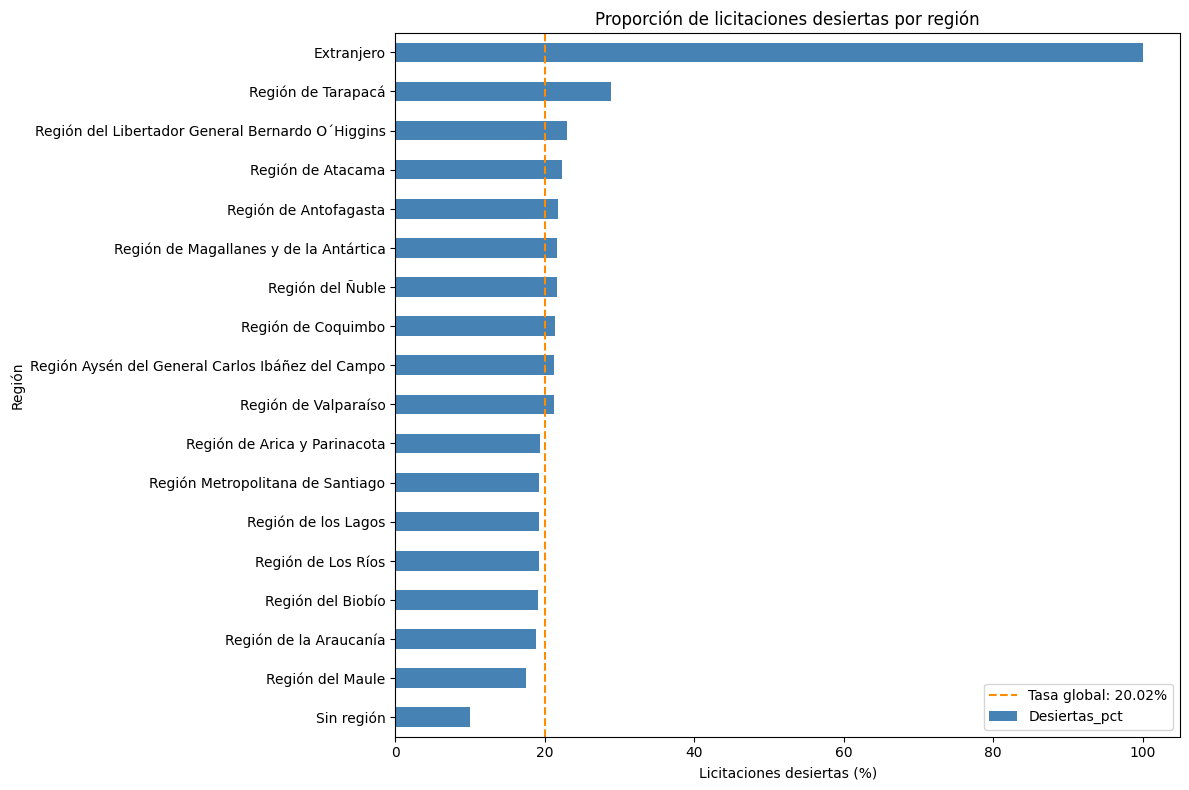

In [229]:
# Relación entre región y variable objetivo (solo entrenamiento).
region_analisis = (train_df["region"].astype("string").str.strip()
                   .replace("", pd.NA).fillna("Sin región"))
relacion_region_objetivo = pd.crosstab(
    region_analisis, train_df[TARGET]
).reindex(columns=[0, 1], fill_value=0)
relacion_region_objetivo.columns = ["No_desiertas", "Desiertas"]
relacion_region_objetivo.index.name = "Región"
relacion_region_objetivo["Registros"] = relacion_region_objetivo.sum(axis=1)
relacion_region_objetivo["Desiertas_pct"] = (
    100 * relacion_region_objetivo["Desiertas"] / relacion_region_objetivo["Registros"]
)
tasa_global_region = 100 * train_df[TARGET].mean()
relacion_region_objetivo["Diferencia_global_pp"] = (
    relacion_region_objetivo["Desiertas_pct"] - tasa_global_region
)
relacion_region_objetivo = relacion_region_objetivo.sort_values("Desiertas_pct", ascending=False)
display(relacion_region_objetivo.round(2))

# Comparar porcentajes permite considerar el distinto tamaño de las regiones.
ax = relacion_region_objetivo["Desiertas_pct"].plot.barh(
    figsize=(12, 8), color="steelblue"
)
ax.axvline(tasa_global_region, color="darkorange", linestyle="--",
           label=f"Tasa global: {tasa_global_region:.2f}%")
ax.invert_yaxis()
ax.set(title="Proporción de licitaciones desiertas por región",
       xlabel="Licitaciones desiertas (%)", ylabel="Región")
ax.legend()
plt.tight_layout()
plt.show()

In [230]:
# Se eliminan las columnas de comprador y RUT del comprador por ser redundantes.
columnas_a_eliminar = ["comprador", "comprador_rut"]
train_df = train_df.drop(columns=columnas_a_eliminar, errors="ignore")
test_df = test_df.drop(columns=columnas_a_eliminar, errors="ignore")

In [231]:
# Se elimina la columna de categoría por ser redundante.
columnas_a_eliminar = ["pub_categoria"]
train_df = train_df.drop(columns=columnas_a_eliminar, errors="ignore")
test_df = test_df.drop(columns=columnas_a_eliminar, errors="ignore")

In [232]:
# Se elimina la columna de categoría por ser insignificante.
columnas_a_eliminar = ["direccion"]
train_df = train_df.drop(columns=columnas_a_eliminar, errors="ignore")
test_df = test_df.drop(columns=columnas_a_eliminar, errors="ignore")

In [233]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152553 entries, 0 to 152552
Data columns (total 20 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152553 non-null  int64  
 1   pub_fecha             152553 non-null  object 
 2   pub_titulo            152544 non-null  object 
 3   pub_descripcion       152544 non-null  object 
 4   pub_monto_estimado    85287 non-null   float64
 5   pub_moneda            85251 non-null   object 
 6   pub_metodo            152485 non-null  object 
 7   pub_modalidad         152553 non-null  object 
 8   pub_n_items           152553 non-null  int64  
 9   pub_cantidad_total    152553 non-null  float64
 10  pub_categoria_id      152528 non-null  float64
 11  pub_n_categorias      152553 non-null  int64  
 12  pub_inicio            152553 non-null  object 
 13  pub_cierre            152526 non-null  object 
 14  pub_dias_postulacion  152530 non-null  float64
 15  

### Separación de variables predictoras y objetivo

Antes de convertir los montos, separamos `train_df` en `x_train`, con las variables predictoras, e `y_train`, con la variable objetivo `y_desierta`. Ambos conservan el índice original para mantener la correspondencia entre filas. A partir de aquí, las transformaciones de entrenamiento se aplican a `x_train`; `y_train` se utiliza para analizar el desenlace.

In [258]:
x_train = train_df.drop(columns=[TARGET]).copy()
y_train = train_df[TARGET].copy()

print(f"x_train: {x_train.shape} | y_train: {y_train.shape}")

x_train: (152553, 19) | y_train: (152553,)


### Conversión a CLP por fecha de publicación

Cada monto se convierte usando `pub_fecha`, interpretada en la zona horaria `America/Santiago`. Se consulta la tasa histórica de USD, EUR o UF (CLF) en [Mindicador](https://mindicador.cl/). Para días sin cotización se usa la última tasa anterior disponible. Los montos en CLP se conservan.

Si falta el monto o la moneda, `monto_clp` se completa con la mediana de los montos válidos convertidos de entrenamiento; esa misma mediana se utiliza en prueba.

Las tasas se guardan en `cache_tasas_clp/` para reutilizarlas incluso después de reiniciar el kernel. Cada descarga permite hasta tres intentos, con 60 segundos de timeout y espera creciente. Solo se solicita el año anterior cuando hace falta una cotización para los primeros días de enero. Si Mindicador sigue sin responder y no existe una caché válida, se detiene la conversión con la URL y el año afectados; los fallos de descarga no se imputan como montos faltantes.

In [259]:
# Convertir según pub_fecha (fecha local de Chile). CLF = UF.
# Fuente histórica: https://mindicador.cl/
import json
import warnings
from functools import lru_cache
from http.client import HTTPException
from pathlib import Path
from time import sleep
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

INDICADORES_CLP = {"USD": "dolar", "EUR": "euro", "CLF": "uf"}
CACHE_TASAS_CLP = Path("cache_tasas_clp")
TIMEOUT_TASAS_CLP = 60
INTENTOS_TASAS_CLP = 3


def _extraer_tasas_clp(datos, indicador, anio):
    if (not isinstance(datos, dict) or datos.get("codigo") != indicador
            or datos.get("unidad_medida") != "Pesos"
            or not isinstance(datos.get("serie"), list)):
        raise ValueError(f"Respuesta inválida para {indicador}, {anio}")
    serie = pd.DataFrame(datos["serie"])
    if serie.empty or not {"fecha", "valor"}.issubset(serie.columns):
        raise ValueError(f"No hay tasas en CLP para {indicador}, {anio}")
    fechas = (pd.to_datetime(serie["fecha"], utc=True)
              .dt.tz_convert("America/Santiago").dt.tz_localize(None).dt.normalize())
    valores = pd.to_numeric(serie["valor"], errors="raise").to_numpy(dtype="float64")
    if fechas.isna().any() or not np.isfinite(valores).all() or (valores <= 0).any():
        raise ValueError(f"Fechas o tasas inválidas para {indicador}, {anio}")
    tasas = pd.Series(valores,
                      index=pd.DatetimeIndex(fechas), dtype="float64").sort_index()
    return tasas.loc[~tasas.index.duplicated(keep="last")]


@lru_cache(maxsize=None)
def cargar_tasas_clp(indicador, anio):
    url = f"https://mindicador.cl/api/{indicador}/{anio}"
    archivo = CACHE_TASAS_CLP / f"{indicador}_{anio}.json"
    # Los años en curso se descargan de nuevo al iniciar otra sesión.
    if archivo.exists() and anio < pd.Timestamp.now(tz="America/Santiago").year:
        try:
            return _extraer_tasas_clp(
                json.loads(archivo.read_text(encoding="utf-8")), indicador, anio
            )
        except (OSError, ValueError, TypeError) as error:
            warnings.warn(f"Caché inválida {archivo}: {error}. Se descargará otra vez.")

    for intento in range(1, INTENTOS_TASAS_CLP + 1):
        print(f"Descargando {indicador}/{anio} (intento {intento}/{INTENTOS_TASAS_CLP})",
              flush=True)
        try:
            peticion = Request(url, headers={"Accept": "application/json"})
            with urlopen(peticion, timeout=TIMEOUT_TASAS_CLP) as respuesta:
                datos = json.load(respuesta)
            tasas = _extraer_tasas_clp(datos, indicador, anio)
        except HTTPError as error:
            error.close()
            if error.code not in {408, 429} and not 500 <= error.code < 600:
                raise RuntimeError(f"HTTP {error.code} al consultar {url}") from error
            ultimo_error = error
        except (TimeoutError, URLError, OSError, HTTPException, ValueError, TypeError) as error:
            ultimo_error = error
        else:
            # Guardar solo respuestas validadas; replace evita archivos incompletos.
            CACHE_TASAS_CLP.mkdir(parents=True, exist_ok=True)
            temporal = archivo.with_suffix(".tmp")
            temporal.write_text(json.dumps(datos, ensure_ascii=False), encoding="utf-8")
            temporal.replace(archivo)
            return tasas
        if intento < INTENTOS_TASAS_CLP:
            espera = 2 ** intento
            print(f"Falló {indicador}/{anio}: {ultimo_error}. Reintento en {espera} s.",
                  flush=True)
            sleep(espera)

    raise RuntimeError(
        f"No se pudieron cargar las tasas de {indicador}, {anio}, tras "
        f"{INTENTOS_TASAS_CLP} intentos: {url}. No hay caché válida en {archivo}. "
        "Comprueba la conexión o vuelve a ejecutar esta celda cuando Mindicador responda."
    ) from ultimo_error


def convertir_montos_a_clp(df):
    monto = pd.to_numeric(df["pub_monto_estimado"], errors="raise")
    moneda = df["pub_moneda"].astype("string").str.strip().str.upper().replace("", pd.NA)
    completos = monto.notna() & moneda.notna()
    desconocidas = set(moneda.loc[completos]) - {"CLP", *INDICADORES_CLP}
    if desconocidas:
        raise ValueError(f"Monedas sin tasa: {sorted(desconocidas)}")

    resultado = pd.Series(np.nan, index=df.index, name="monto_clp", dtype="float64")
    es_clp = completos & moneda.eq("CLP").fillna(False)
    resultado.loc[es_clp] = monto.loc[es_clp]
    fechas = (pd.to_datetime(df["pub_fecha"], utc=True, errors="coerce")
              .dt.tz_convert("America/Santiago").dt.tz_localize(None).dt.normalize())

    for codigo, indicador in INDICADORES_CLP.items():
        convertir = completos & moneda.eq(codigo).fillna(False)
        if not convertir.any():
            continue
        fechas_moneda = fechas.loc[convertir]
        if fechas_moneda.isna().any():
            raise ValueError(f"Falta pub_fecha válida para convertir {codigo}")
        anios = range(fechas_moneda.min().year, fechas_moneda.max().year + 1)
        tasas = pd.concat([
            cargar_tasas_clp(indicador, anio)
            for anio in anios
        ]).sort_index()
        # Consultar el año previo solo si faltan tasas al inicio de enero.
        if tasas.index.min() > fechas_moneda.min():
            tasas = pd.concat([cargar_tasas_clp(indicador, anios[0] - 1), tasas]).sort_index()
        tasas = tasas.loc[~tasas.index.duplicated(keep="last")]
        # Usar la tasa de ese día o la última anterior; nunca una futura.
        factores = tasas.reindex(pd.DatetimeIndex(fechas_moneda), method="ffill").to_numpy()
        if pd.isna(factores).any():
            raise ValueError(f"No hay tasa anterior disponible para {codigo}")
        resultado.loc[convertir] = monto.loc[convertir].to_numpy() * factores
    return resultado


# Completar ambas conversiones antes de modificar los DataFrames.
montos_convertidos = [convertir_montos_a_clp(df) for df in (x_train, test_df)]

# Imputar faltantes con la mediana de los montos convertidos de entrenamiento.
mediana_monto_clp = montos_convertidos[0].median()
if pd.isna(mediana_monto_clp):
    raise ValueError("No hay montos válidos en entrenamiento para calcular la mediana")
for df_actual, montos_clp in zip((x_train, test_df), montos_convertidos):
    df_actual["monto_clp"] = montos_clp.fillna(mediana_monto_clp)

### Intervalos del monto sin valores atípicos

Usamos `monto_clp`, que ya incluye la imputación de faltantes con la mediana de entrenamiento. Excluimos valores fuera de **[Q1 − 1,5 × RIQ, Q3 + 1,5 × RIQ]**, donde RIQ = Q3 − Q1. El filtro se aplica solo a este análisis.

Se construyen **seis intervalos de igual amplitud en CLP**, entre el monto mínimo y el máximo después del filtro, mediante `pd.cut`. Los intervalos pueden tener distinta cantidad de registros o quedar vacíos; todos se muestran en la tabla. Los montos iguales, incluidos los imputados con la mediana, quedan en el mismo intervalo. La tabla muestra los conteos por clase, la tasa de desiertas y cuántos montos fueron imputados porque el monto o la moneda original era nulo.

In [260]:
montos = x_train.loc[
    x_train["monto_clp"].notna(),
    ["monto_clp"]
].copy()
montos[TARGET] = y_train.reindex(montos.index)
montos["Monto_imputado"] = (
    x_train["pub_monto_estimado"].isna() | x_train["pub_moneda"].isna()
).reindex(montos.index)
q1, q3 = montos["monto_clp"].quantile([0.25, 0.75])
riq = q3 - q1
conservar = montos["monto_clp"].between(q1 - 1.5 * riq, q3 + 1.5 * riq)
print(f"Montos atípicos excluidos: {(~conservar).sum()}")
montos = montos.loc[conservar].copy()
# Seis intervalos de igual amplitud; los montos iguales quedan juntos.
montos["Intervalo"], bordes_monto_clp = pd.cut(
    montos["monto_clp"], bins=6, include_lowest=True, retbins=True
)
print(f"Intervalos obtenidos: {len(bordes_monto_clp) - 1}")
display(montos.groupby("Intervalo", observed=False).agg(
    Registros=(TARGET, "size"),
    Montos_imputados=("Monto_imputado", "sum"),
    No_desiertas=(TARGET, lambda y: y.eq(0).sum()),
    Desiertas=(TARGET, "sum"),
    Desiertas_pct=(TARGET, lambda y: 100 * y.mean())
).round(2))

Montos atípicos excluidos: 48233
Intervalos obtenidos: 6


,Registros,Montos_imputados,No_desiertas,Desiertas,Desiertas_pct
Intervalo,,,,,
"(3286832.999, 4656166.667]",11383,0,9141,2242,19.70
"(4656166.667, 6017333.333]",10249,0,8333,1916,18.69
"(6017333.333, 7378500.0]",76042,67302,61169,14873,19.56
"(7378500.0, 8739666.667]",2473,0,2009,464,18.76
"(8739666.667, 10100833.333]",2896,0,2287,609,21.03
"(10100833.333, 11462000.0]",1277,0,1028,249,19.50


### Distribución de los montos

El histograma muestra **todos los montos de entrenamiento en millones de CLP**, incluidos los imputados y los valores atípicos. Se utiliza directamente `x_train["monto_clp"]`, sin aplicar el filtro de la tabla anterior.

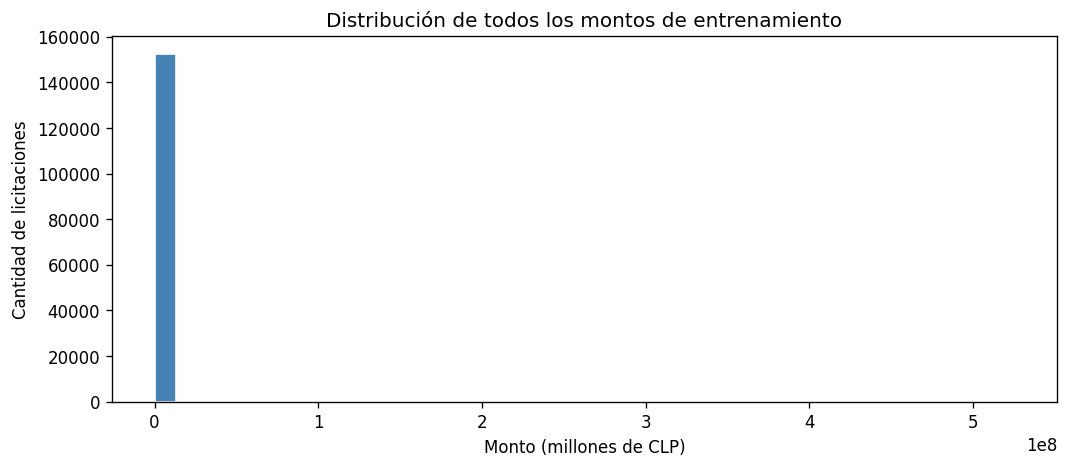

In [261]:
montos_grafico = x_train["monto_clp"].dropna() / 1_000_000
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(montos_grafico, bins=40, color="steelblue", edgecolor="white")
ax.set(title="Distribución de todos los montos de entrenamiento",
       xlabel="Monto (millones de CLP)", ylabel="Cantidad de licitaciones")
plt.tight_layout()
plt.show()

# 2. Feature engineering

### Matriz de correlación de variables numéricas

Se analiza `x_train` junto con `y_train` para estudiar la relación entre los predictores y el desenlace. Se excluyen `id` y `pub_categoria_id`, porque sus números identifican registros o categorías, y `pub_monto_estimado`, porque mezcla monedas y ya contamos con `monto_clp`.

Se utiliza **Spearman** para comparar relaciones monótonas sin que la magnitud de los montos extremos domine el análisis. La tabla complementaria incluye también Pearson. Las variables constantes o sin datos se excluyen porque su correlación no está definida. El texto y las categorías requieren otras técnicas y se conservan en `x_train`.


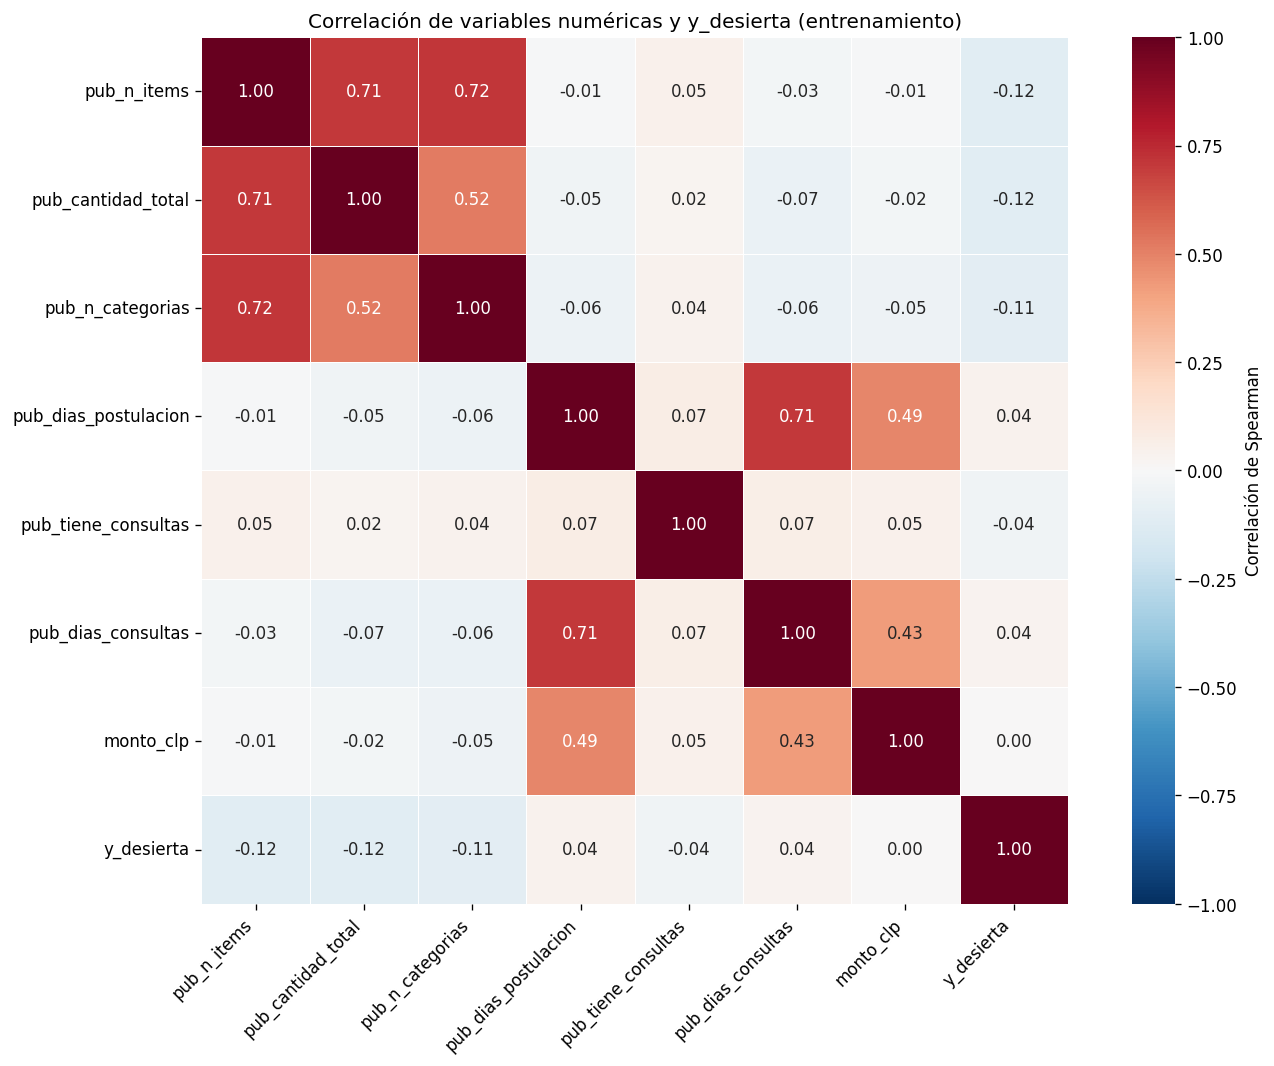

In [262]:
# Solo entrenamiento: no se consulta test_df para decidir las variables.
columnas_excluidas_correlacion = ["id", "pub_categoria_id", "pub_monto_estimado"]
x_correlacion = (
    x_train.select_dtypes(include=["number", "bool"])
    .drop(columns=columnas_excluidas_correlacion, errors="ignore")
    .replace([np.inf, -np.inf], np.nan)
)
columnas_constantes = x_correlacion.columns[
    x_correlacion.nunique(dropna=True).le(1)
].tolist()
x_correlacion = x_correlacion.drop(columns=columnas_constantes)
if x_correlacion.empty:
    raise ValueError("No hay variables numéricas con variación para calcular la correlación")

datos_correlacion = x_correlacion.copy()
datos_correlacion[TARGET] = y_train.reindex(x_correlacion.index)
matriz_correlacion = datos_correlacion.corr(method="spearman")
matriz_correlacion_pearson = datos_correlacion.corr(method="pearson")

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    matriz_correlacion, annot=True, fmt=".2f", cmap="RdBu_r",
    vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
    cbar_kws={"label": "Correlación de Spearman"}, ax=ax
)
ax.set_title("Correlación de variables numéricas y y_desierta (entrenamiento)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

if columnas_constantes:
    print("Variables constantes o sin datos excluidas:", columnas_constantes)


### Apoyo a la selección de variables

La tabla ordena los predictores por su correlación absoluta de Spearman con `y_desierta`. El signo indica la dirección de la asociación. Una correlación pequeña con el objetivo no basta para descartar una variable: podría aportar mediante relaciones no lineales o interacciones.

Como propuesta inicial para las variables numéricas, se retiene la mejor posicionada en el ranking cuando dos predictores tienen **|correlación de Spearman| ≥ 0,90**. Se muestran las exclusiones y el predictor conservado. El umbral se puede ajustar en `umbral_redundancia`.

Esta selección es exploratoria. Para comparar modelos, debe recalcularse dentro del entrenamiento de cada partición temporal y confirmarse por su desempeño en validación. No se eliminan las variables originales de `x_train`, ni se seleccionan aquí las variables de texto y categóricas.


In [263]:
ranking_correlacion = pd.DataFrame({
    "Spearman_objetivo": matriz_correlacion.loc[x_correlacion.columns, TARGET],
    "Pearson_objetivo": matriz_correlacion_pearson.loc[x_correlacion.columns, TARGET],
    "Faltantes_pct": 100 * x_correlacion.isna().mean()
})
ranking_correlacion["Abs_Spearman"] = ranking_correlacion["Spearman_objetivo"].abs()
ranking_correlacion = ranking_correlacion.sort_values("Abs_Spearman", ascending=False)
ranking_correlacion.index.name = "Variable"
display(ranking_correlacion.round(4))

umbral_redundancia = 0.90
variables_numericas_seleccionadas = []
exclusiones_correlacion = []
for variable in ranking_correlacion.index:
    correlaciones_previas = matriz_correlacion.loc[
        variable, variables_numericas_seleccionadas
    ].abs()
    if correlaciones_previas.ge(umbral_redundancia).any():
        conservada = correlaciones_previas.idxmax()
        exclusiones_correlacion.append({
            "Variable_excluida": variable,
            "Variable_conservada": conservada,
            "Abs_Spearman_entre_variables": correlaciones_previas[conservada]
        })
    else:
        variables_numericas_seleccionadas.append(variable)

if exclusiones_correlacion:
    display(pd.DataFrame(exclusiones_correlacion).round(4))
else:
    print(f"No hay variables numéricas redundantes con el umbral {umbral_redundancia:.2f}.")

print("Propuesta de variables numéricas para los modelos:")
print(variables_numericas_seleccionadas)


,Spearman_objetivo,Pearson_objetivo,Faltantes_pct,Abs_Spearman
Variable,,,,
pub_cantidad_total,-0.1167,-0.0052,0.0000,0.1167
pub_n_items,-0.1163,-0.0610,0.0000,0.1163
pub_n_categorias,-0.1058,-0.0663,0.0000,0.1058
pub_dias_postulacion,0.0426,0.0493,0.0151,0.0426
pub_tiene_consultas,-0.0410,-0.0410,0.0000,0.0410
pub_dias_consultas,0.0389,0.0464,0.0446,0.0389
monto_clp,0.0019,0.0011,0.0000,0.0019


No hay variables numéricas redundantes con el umbral 0.90.
Propuesta de variables numéricas para los modelos:
['pub_cantidad_total', 'pub_n_items', 'pub_n_categorias', 'pub_dias_postulacion', 'pub_tiene_consultas', 'pub_dias_consultas', 'monto_clp']


### Lectura de los resultados

Con los datos actuales, las mayores asociaciones de Spearman con `y_desierta` corresponden a `pub_cantidad_total` (aproximadamente −0,117), `pub_n_items` (−0,116) y `pub_n_categorias` (−0,106). Todas son bajas, por lo que estas variables por separado distinguen poco el desenlace.

Ningún par de predictores alcanza el umbral de redundancia de 0,90. La propuesta inicial conserva las siete variables numéricas; su aporte, incluido el de `monto_clp`, se debe comprobar al comparar los modelos en validación temporal.

### Variables para comparar los modelos

La matriz anterior orienta el bloque numérico. La correlación baja con el objetivo no permite escoger por sí sola el modelo, por lo que se comparan una regresión logística numérica, regresiones logísticas con estructura y texto, un árbol, Random Forest y boosting de gradiente, junto con una referencia sin información.

Se agregan longitudes del título y la descripción, mes y día de publicación y una indicadora de plazo inconsistente. Las categorías, incluidos comprador y rubro, se codifican con one-hot y agrupación de categorías infrecuentes; sus códigos no se interpretan como cantidades. El texto combina título y descripción mediante TF-IDF.

Para modelar, los montos originalmente ausentes vuelven a marcarse como faltantes: la mediana usada en el análisis descriptivo se reemplaza por una mediana aprendida dentro de cada entrenamiento. Lo mismo ocurre con la selección por correlación, la escala, las categorías y el vocabulario. No se reutiliza la selección supervisada calculada sobre todo 2024.


In [264]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import FunctionTransformer
from time import perf_counter


def construir_features_modelo(df):
    datos = df.copy()
    fechas = pd.to_datetime(datos["pub_fecha"], utc=True, errors="coerce")
    cierres = pd.to_datetime(datos["pub_cierre"], utc=True, errors="coerce")
    moneda = datos["pub_moneda"].astype("string").str.strip().fillna("")
    monto_ausente = datos["pub_monto_estimado"].isna() | moneda.eq("")
    datos["monto_clp"] = datos["monto_clp"].mask(monto_ausente)
    datos["longitud_titulo"] = datos["pub_titulo"].fillna("").str.len()
    datos["longitud_descripcion"] = datos["pub_descripcion"].fillna("").str.len()
    fechas_locales = fechas.dt.tz_convert("America/Santiago")
    datos["pub_mes"] = fechas_locales.dt.month
    datos["pub_dia_semana"] = fechas_locales.dt.dayofweek
    datos["plazo_inconsistente"] = cierres.lt(fechas).astype(int)
    datos["texto_bases"] = (
        datos["pub_titulo"].fillna("") + " " + datos["pub_descripcion"].fillna("")
    )
    categorias = ["pub_metodo", "pub_modalidad", "pub_moneda",
                  "region", "comprador_id", "pub_categoria_id"]
    for columna in categorias:
        datos[columna] = datos[columna].astype("string").fillna("Sin dato").astype(str)
    return datos


x_modelos = construir_features_modelo(x_train)
x_prueba_modelos = construir_features_modelo(test_df)
columnas_numericas_modelo = [
    "monto_clp", "pub_n_items", "pub_cantidad_total", "pub_n_categorias",
    "pub_dias_postulacion", "pub_tiene_consultas", "pub_dias_consultas",
    "longitud_titulo", "longitud_descripcion", "pub_mes",
    "pub_dia_semana", "plazo_inconsistente"
]
columnas_categoricas_modelo = [
    "pub_metodo", "pub_modalidad", "pub_moneda", "region",
    "comprador_id", "pub_categoria_id"
]
for datos in (x_modelos, x_prueba_modelos):
    datos[columnas_numericas_modelo] = (
        datos[columnas_numericas_modelo].astype(float)
        .replace([np.inf, -np.inf], np.nan)
    )
    datos[columnas_numericas_modelo] = datos[columnas_numericas_modelo].where(
        datos[columnas_numericas_modelo].ge(0)
    )


# 3. Trimestres y validación cruzada temporal

Se consideran **todos los registros publicados entre el 01-01-2024 y el 31-12-2024**, según `America/Santiago`. Los cortes son inclusivos por la izquierda y exclusivos por la derecha, usando el 01-01-2025 como límite superior para incluir todo el último día de diciembre:

| Bloque | Fechas | Uso |
|---|---|---|
| T1 | 01-01 a 31-03 | Entrenamiento inicial |
| T2 | 01-04 a 30-06 | Validación del fold 1 |
| T3 | 01-07 a 30-09 | Validación del fold 2 |
| T4 | 01-10 a 31-12 | Evaluación final reservada |

Los folds son **T1 → T2** y **T1+T2 → T3**. El entrenamiento se amplía y cada ventana de validación mantiene tres meses. Los trimestres tienen la misma duración en meses; sus cantidades de licitaciones y días pueden ser distintas. No se mezclan filas futuras en el entrenamiento.

Se conserva el criterio de disponibilidad **cierre + 30 días**. Cada entrenamiento utiliza solo etiquetas maduras en su corte. Para seleccionar el modelo y su umbral antes de T4, se puntúan solo las etiquetas de T2 y T3 disponibles al 01-10-2024. Se predice todo cada trimestre y se informa por separado cuántos casos pueden puntuarse bajo este criterio. Las fechas inconsistentes impiden usar la etiqueta en entrenamiento o selección, pero no impiden predecir la fila.

T4 completo se evalúa retrospectivamente con las etiquetas entregadas en el dataset, también cuando su desenlace se habría conocido en 2025. Sus etiquetas no participan en la selección ni en el umbral. Por esto hay **dos folds de CV y un trimestre reservado**, en vez de reutilizar T4 como un tercer fold para elegir modelos.


In [265]:
fecha_publicacion_modelos = pd.to_datetime(x_train["pub_fecha"], utc=True, errors="coerce").dt.tz_convert("America/Santiago")
fecha_cierre_modelos = pd.to_datetime(x_train["pub_cierre"], utc=True, errors="coerce")
cierre_valido_modelos = (
    fecha_publicacion_modelos.notna() & fecha_cierre_modelos.notna()
    & fecha_cierre_modelos.ge(fecha_publicacion_modelos)
)
fecha_etiqueta_modelos = (fecha_cierre_modelos + pd.Timedelta(days=30)).where(cierre_valido_modelos)
cortes_trimestrales = pd.date_range("2024-01-01", "2025-01-01", freq="QS", tz="America/Santiago")
mascara_2024 = fecha_publicacion_modelos.ge(cortes_trimestrales[0]) & fecha_publicacion_modelos.lt(cortes_trimestrales[-1])
corte_decision_modelos = cortes_trimestrales[3]
primera_fecha_prueba = pd.to_datetime(test_df["pub_fecha"], utc=True, errors="coerce").min()

mascaras_trimestres = {}
resumen_trimestres = []
for i in range(4):
    trimestre = f"T{i + 1}"
    mascara = fecha_publicacion_modelos.ge(cortes_trimestrales[i]) & fecha_publicacion_modelos.lt(cortes_trimestrales[i + 1])
    mascaras_trimestres[trimestre] = mascara
    resumen_trimestres.append({
        "Trimestre": trimestre,
        "Inicio": cortes_trimestrales[i].strftime("%d-%m-%Y"),
        "Fin": (cortes_trimestrales[i + 1] - pd.Timedelta(days=1)).strftime("%d-%m-%Y"),
        "Registros": int(mascara.sum()),
        "Desiertas_pct": 100 * y_train.loc[mascara].mean()
    })
resumen_trimestres = pd.DataFrame(resumen_trimestres)
assert sum(int(m.sum()) for m in mascaras_trimestres.values()) == int(mascara_2024.sum())
assert pd.concat(mascaras_trimestres, axis=1).sum(axis=1).le(1).all()
display(resumen_trimestres.round(2))

folds_temporales = []
resumen_folds = []
for i in (1, 2):
    entrenamiento = mascara_2024 & fecha_publicacion_modelos.lt(cortes_trimestrales[i]) & fecha_etiqueta_modelos.lt(cortes_trimestrales[i])
    validacion = mascaras_trimestres[f"T{i + 1}"]
    puntuacion = validacion & fecha_etiqueta_modelos.lt(corte_decision_modelos)
    if not entrenamiento.any() or not puntuacion.any():
        raise ValueError(f"Fold {i} sin casos admisibles")
    if y_train.loc[entrenamiento].nunique() != 2 or y_train.loc[puntuacion].nunique() != 2:
        raise ValueError(f"Fold {i} no contiene ambas clases")
    assert not (entrenamiento & validacion).any()
    folds_temporales.append({"Fold": i, "Entrenamiento": entrenamiento,
                             "Validacion": validacion, "Puntuacion": puntuacion})
    resumen_folds.append({
        "Fold": i, "Entrenamiento": "T1" if i == 1 else "T1+T2",
        "Validación": f"T{i + 1}", "Filas_ajuste": int(entrenamiento.sum()),
        "Filas_predichas": int(validacion.sum()), "Filas_puntuadas": int(puntuacion.sum()),
        "Corte_etiquetas_ajuste": cortes_trimestrales[i].strftime("%d-%m-%Y")
    })
resumen_folds = pd.DataFrame(resumen_folds)
display(resumen_folds)
mascara_oof_seleccion = (mascaras_trimestres["T2"] | mascaras_trimestres["T3"]) & fecha_etiqueta_modelos.lt(corte_decision_modelos)
mascara_evaluacion = mascaras_trimestres["T4"]
mascara_ajuste_evaluacion = mascara_2024 & fecha_publicacion_modelos.lt(corte_decision_modelos) & fecha_etiqueta_modelos.lt(corte_decision_modelos)
print("Registros 2024:", int(mascara_2024.sum()), "| Fuera de período o sin fecha:", int((~mascara_2024).sum()))
print("Cierres ausentes o anteriores a publicación:", int((~cierre_valido_modelos).sum()))
print("Evaluación reservada T4 completo:", int(mascara_evaluacion.sum()))


,Trimestre,Inicio,Fin,Registros,Desiertas_pct
0,T1,01-01-2024,31-03-2024,35790,20.07
1,T2,01-04-2024,30-06-2024,41185,20.14
2,T3,01-07-2024,30-09-2024,39691,19.85
3,T4,01-10-2024,31-12-2024,35887,20.04


,Fold,Entrenamiento,Validación,Filas_ajuste,Filas_predichas,Filas_puntuadas,Corte_etiquetas_ajuste
0,1,T1,T2,17231,41185,38714,01-04-2024
1,2,T1+T2,T3,54499,39691,21231,01-07-2024


Registros 2024: 152553 | Fuera de período o sin fecha: 0
Cierres ausentes o anteriores a publicación: 11336
Evaluación reservada T4 completo: 35887


# 4. Modelos, XGBoost, ensamblajes y cross validation

Se conservan los modelos y votaciones anteriores y se incorporan tres configuraciones de XGBoost. Además se comparan votaciones logística + XGBoost con pesos 1:1 y 2:1, y logística + Random Forest + XGBoost con pesos 4:1:1. El componente XGBoost de estas votaciones se fija de antemano en la variante con texto; no se elige usando T4.

### XGBoost mediante una función

`crear_modelo_xgboost` construye el clasificador y su pipeline. XGBoost empieza con una predicción inicial y añade árboles que corrigen el modelo anterior, minimizando una función objetivo con pérdida y regularización. Para esta clasificación binaria se utiliza `objective="binary:logistic"`; la métrica de seguimiento es `aucpr`. F1 se optimiza después mediante el umbral OOF.

| Configuración | Profundidad | Árboles | Texto |
|---|---:|---:|---|
| XGBoost estructural profundidad 3 | 3 | 300 | Sin TF-IDF |
| XGBoost estructural profundidad 5 | 5 | 300 | Sin TF-IDF |
| XGBoost estructura y texto | 3 | 250 | TF-IDF, máximo 10.000 términos |

Parámetros comunes: `learning_rate=0.05`, `min_child_weight=10`, `subsample=0.8`, `colsample_bytree=0.8`, `reg_lambda=10`, `reg_alpha=0.1`, `max_bin=128`, `tree_method="hist"`, `n_jobs=2` y `random_state=42`. Las cantidades de árboles están fijadas antes de evaluar: no se usa T4 para early stopping.

Cada fold aprende únicamente su selección por correlación, imputación, transformación, escala, categorías y vocabulario. Se selecciona por AP media entre folds y se fija el umbral con OOF. La CV reutiliza las probabilidades de los componentes para calcular las votaciones sin repetir entrenamientos idénticos.

Se usa XGBoost 3.4.1. La dependencia adicional queda en `requirements-modelos.txt`; la instalación local de este proyecto está en `.dependencias_ml/`. En otro entorno puede instalarse con `%pip install -r requirements-modelos.txt`.

Fuentes: [función objetivo y entrenamiento aditivo de XGBoost](https://xgboost.readthedocs.io/en/stable/tutorials/model.html) y [parámetros oficiales](https://xgboost.readthedocs.io/en/stable/parameter.html).


In [266]:
from sklearn.ensemble import VotingClassifier

class SelectorCorrelacionNumerica(TransformerMixin, BaseEstimator):
    def __init__(self, umbral=0.90):
        self.umbral = umbral

    def fit(self, X, y):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        variables = X.columns[X.nunique(dropna=True).gt(1)].tolist()
        if not variables:
            raise ValueError("No hay predictores numéricos con variación en entrenamiento")
        datos = X.loc[:, variables].copy()
        datos["_objetivo_"] = np.asarray(y)
        corr = datos.corr(method="spearman")
        orden = corr["_objetivo_"].drop("_objetivo_").abs().sort_values(
            ascending=False, kind="stable"
        ).index
        self.variables_ = []
        for variable in orden:
            if not corr.loc[variable, self.variables_].abs().ge(self.umbral).any():
                self.variables_.append(variable)
        return self

    def transform(self, X):
        return X.loc[:, self.variables_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.variables_, dtype=object)


def crear_preprocesador_modelo(con_texto=False, solo_numericas=False):
    numericas = Pipeline([
        ("seleccion", SelectorCorrelacionNumerica(umbral=0.90)),
        ("imputacion", SimpleImputer(strategy="median", add_indicator=True)),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("escala", StandardScaler())
    ])
    bloques = [("numericas", numericas, columnas_numericas_modelo)]
    if not solo_numericas:
        bloques.append(("categoricas", OneHotEncoder(
            handle_unknown="infrequent_if_exist", min_frequency=100,
            max_categories=60, sparse_output=con_texto
        ), columnas_categoricas_modelo))
    if con_texto:
        bloques.append(("texto", TfidfVectorizer(
            strip_accents="unicode", ngram_range=(1, 2), min_df=3,
            max_features=30000, sublinear_tf=True
        ), "texto_bases"))
    return ColumnTransformer(bloques, sparse_threshold=1.0 if con_texto else 0.0)


def crear_pipeline_modelo(estimador, con_texto=False, solo_numericas=False):
    return Pipeline([
        ("preparacion", crear_preprocesador_modelo(con_texto, solo_numericas)),
        ("modelo", estimador)
    ])


candidatos_modelos = {
    "Referencia prevalencia": crear_pipeline_modelo(
        DummyClassifier(strategy="prior"), solo_numericas=True),
    "Logística numérica": crear_pipeline_modelo(
        LogisticRegression(C=1.0, max_iter=1000, solver="liblinear", random_state=SEED),
        solo_numericas=True),
    "Logística estructura y texto C=0.5": crear_pipeline_modelo(
        LogisticRegression(C=0.5, max_iter=1000, solver="liblinear", random_state=SEED),
        con_texto=True),
    "Logística estructura y texto C=2": crear_pipeline_modelo(
        LogisticRegression(C=2.0, max_iter=1000, solver="liblinear", random_state=SEED),
        con_texto=True),
    "Árbol estructural": crear_pipeline_modelo(
        DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                               class_weight="balanced", random_state=SEED)),
    "Random Forest estructural": crear_pipeline_modelo(
        RandomForestClassifier(n_estimators=160, max_depth=16, min_samples_leaf=20,
                               class_weight="balanced_subsample", n_jobs=2,
                               random_state=SEED)),
    "Boosting estructural": crear_pipeline_modelo(
        HistGradientBoostingClassifier(max_iter=180, learning_rate=0.06,
                                       max_leaf_nodes=15, l2_regularization=10,
                                       early_stopping=False, random_state=SEED))
}




# Dependencia adicional: preferir la instalación local del proyecto si existe.
import sys
ruta_dependencias_ml = Path(".dependencias_ml").resolve()
if ruta_dependencias_ml.exists() and str(ruta_dependencias_ml) not in sys.path:
    sys.path.insert(0, str(ruta_dependencias_ml))
try:
    from xgboost import XGBClassifier
except ModuleNotFoundError as error:
    raise ModuleNotFoundError("Instala la dependencia adicional con %pip install -r requirements-modelos.txt") from error


def crear_modelo_xgboost(max_depth=3, n_estimators=300, con_texto=False):
    estimador = XGBClassifier(
        objective="binary:logistic", eval_metric="aucpr", booster="gbtree",
        n_estimators=n_estimators, max_depth=max_depth, learning_rate=0.05,
        min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=10, reg_alpha=0.1, scale_pos_weight=1.0,
        tree_method="hist", max_bin=128, device="cpu", n_jobs=2,
        random_state=SEED, verbosity=0
    )
    pipeline = crear_pipeline_modelo(estimador, con_texto=con_texto)
    if con_texto:
        pipeline.set_params(preparacion__texto__max_features=10000)
    return pipeline


candidatos_modelos.update({
    "XGBoost estructural profundidad 3": crear_modelo_xgboost(max_depth=3),
    "XGBoost estructural profundidad 5": crear_modelo_xgboost(max_depth=5),
    "XGBoost estructura y texto": crear_modelo_xgboost(max_depth=3, n_estimators=250, con_texto=True)
})

bases_originales = ["Logística estructura y texto C=0.5", "Random Forest estructural", "Boosting estructural"]
configuraciones_votacion = {
    "Votación suave 1:1:1": {"bases": bases_originales, "pesos": [1, 1, 1]},
    "Votación suave 2:1:1": {"bases": bases_originales, "pesos": [2, 1, 1]},
    "Votación suave 4:1:1": {"bases": bases_originales, "pesos": [4, 1, 1]},
    "Votación LR+XGB 1:1": {"bases": ["Logística estructura y texto C=0.5", "XGBoost estructura y texto"], "pesos": [1, 1]},
    "Votación LR+XGB 2:1": {"bases": ["Logística estructura y texto C=0.5", "XGBoost estructura y texto"], "pesos": [2, 1]},
    "Votación LR+RF+XGB 4:1:1": {"bases": ["Logística estructura y texto C=0.5", "Random Forest estructural", "XGBoost estructura y texto"], "pesos": [4, 1, 1]}
}
pesos_votacion = {nombre: config["pesos"] for nombre, config in configuraciones_votacion.items()}
candidatos_ensamble = {
    nombre: VotingClassifier(
        estimators=[(f"modelo_{i}", clone(candidatos_modelos[base])) for i, base in enumerate(config["bases"])],
        voting="soft", weights=config["pesos"], n_jobs=1
    ) for nombre, config in configuraciones_votacion.items()
}
todos_candidatos = {**candidatos_modelos, **candidatos_ensamble}


Fold 1: 17,231 entrenamiento; 41,185 validación trimestral
  Entrenando Referencia prevalencia
    AP=0.2095; ajuste=0.1 s
  Entrenando Logística numérica
    AP=0.2563; ajuste=0.1 s
  Entrenando Logística estructura y texto C=0.5
    AP=0.3138; ajuste=3.5 s
  Entrenando Logística estructura y texto C=2
    AP=0.3055; ajuste=4.4 s
  Entrenando Árbol estructural
    AP=0.2533; ajuste=0.4 s
  Entrenando Random Forest estructural
    AP=0.2850; ajuste=1.9 s
  Entrenando Boosting estructural
    AP=0.2823; ajuste=1.1 s
  Entrenando XGBoost estructural profundidad 3
    AP=0.2829; ajuste=1.1 s
  Entrenando XGBoost estructural profundidad 5
    AP=0.2802; ajuste=1.2 s
  Entrenando XGBoost estructura y texto
    AP=0.3012; ajuste=10.5 s
Fold 2: 54,499 entrenamiento; 39,691 validación trimestral
  Entrenando Referencia prevalencia
    AP=0.2021; ajuste=0.4 s
  Entrenando Logística numérica
    AP=0.2523; ajuste=0.5 s
  Entrenando Logística estructura y texto C=0.5
    AP=0.3229; ajuste=13.4 s


,Fold,Modelo,AP,ROC_AUC,F1_umbral_0.5,Segundos_ajuste,Filas_ajuste,Filas_puntuadas
0,1,Referencia prevalencia,0.2095,0.5000,0.0000,0.1491,17231,38714
1,1,Logística numérica,0.2563,0.5878,0.0080,0.1464,17231,38714
2,1,Logística estructura y texto C=0.5,0.3138,0.6291,0.1194,3.4721,17231,38714
3,1,Logística estructura y texto C=2,0.3055,0.6201,0.1892,4.3901,17231,38714
4,1,Árbol estructural,0.2533,0.5698,0.2848,0.4074,17231,38714
5,1,Random Forest estructural,0.2850,0.6065,0.3576,1.8670,17231,38714
6,1,Boosting estructural,0.2823,0.6001,0.0466,1.1256,17231,38714
7,1,XGBoost estructural profundidad 3,0.2829,0.6040,0.0421,1.1054,17231,38714
8,1,XGBoost estructural profundidad 5,0.2802,0.6001,0.0438,1.2437,17231,38714
9,1,XGBoost estructura y texto,0.3012,0.6168,0.0232,10.4694,17231,38714


,Modelo,AP_CV_media,AP_CV_std,ROC_AUC_CV_media,F1_umbral_05_CV_media,Segundos_ajuste_CV_media,Ensamble_votacion
0,Votación LR+XGB 2:1,0.3207,0.0067,0.6418,0.0636,29.7529,True
1,Votación LR+XGB 1:1,0.3206,0.0069,0.6420,0.0530,29.7529,True
2,Votación LR+RF+XGB 4:1:1,0.3202,0.0074,0.6417,0.0893,35.9500,True
3,Votación suave 4:1:1,0.3187,0.0087,0.6405,0.0931,18.2477,True
4,Logística estructura y texto C=0.5,0.3183,0.0065,0.6389,0.0996,8.4517,False
5,Votación suave 2:1:1,0.3169,0.0102,0.6391,0.0897,18.2477,True
6,Votación suave 1:1:1,0.3126,0.0119,0.6354,0.0869,18.2477,True
7,Logística estructura y texto C=2,0.3098,0.0060,0.6288,0.1646,11.2669,False
8,XGBoost estructura y texto,0.3034,0.0031,0.6253,0.0310,21.3012,False
9,Boosting estructural,0.2914,0.0129,0.6135,0.0501,3.5988,False


Mejor configuración XGBoost: XGBoost estructura y texto
Mejor modelo individual: Logística estructura y texto C=0.5
Mejor ensamblaje: Votación LR+XGB 2:1
Selección global por AP media de CV: Votación LR+XGB 2:1


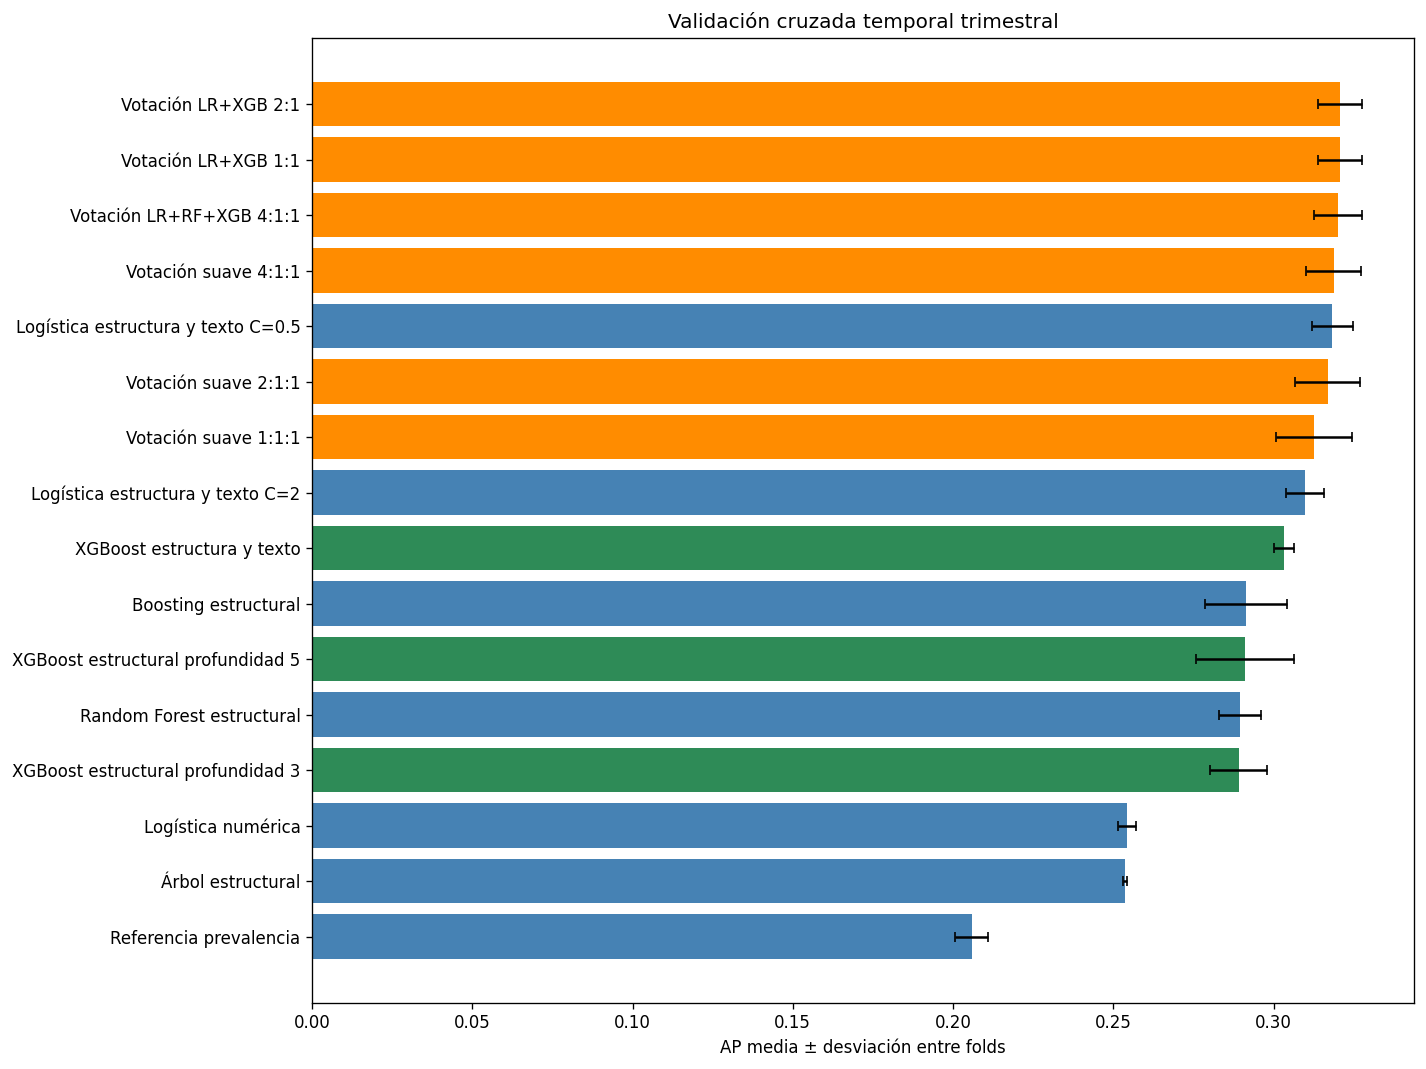

In [267]:
predicciones_oof = pd.DataFrame(np.nan, index=x_modelos.index, columns=list(todos_candidatos))
filas_cv = []


def medir_fold(nombre, fold, probabilidad, segundos):
    mascara = fold["Puntuacion"]
    reales = y_train.loc[mascara]
    pred = (probabilidad >= 0.5).astype(int)
    return {
        "Fold": fold["Fold"], "Modelo": nombre,
        "AP": average_precision_score(reales, probabilidad),
        "ROC_AUC": roc_auc_score(reales, probabilidad),
        "F1_umbral_0.5": f1_score(reales, pred, zero_division=0),
        "Segundos_ajuste": segundos,
        "Filas_ajuste": int(fold["Entrenamiento"].sum()),
        "Filas_puntuadas": int(mascara.sum())
    }


for fold in folds_temporales:
    ajuste = fold["Entrenamiento"]
    validacion = fold["Validacion"]
    puntuacion = fold["Puntuacion"]
    tiempos_componentes = {}
    print(f"Fold {fold['Fold']}: {ajuste.sum():,} entrenamiento; {validacion.sum():,} validación trimestral", flush=True)
    for nombre, candidato in candidatos_modelos.items():
        print(f"  Entrenando {nombre}", flush=True)
        inicio = perf_counter()
        modelo = clone(candidato)
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            modelo.fit(x_modelos.loc[ajuste], y_train.loc[ajuste])
        segundos = perf_counter() - inicio
        tiempos_componentes[nombre] = segundos
        predicciones_oof.loc[validacion, nombre] = modelo.predict_proba(x_modelos.loc[validacion])[:, 1]
        fila = medir_fold(nombre, fold, predicciones_oof.loc[puntuacion, nombre].to_numpy(), segundos)
        filas_cv.append(fila)
        print(f"    AP={fila['AP']:.4f}; ajuste={segundos:.1f} s", flush=True)
        del modelo
    for nombre, config in configuraciones_votacion.items():
        bases_votacion = config["bases"]
        pesos = config["pesos"]
        predicciones_oof.loc[validacion, nombre] = np.average(
            predicciones_oof.loc[validacion, bases_votacion].to_numpy(), axis=1, weights=pesos)
        filas_cv.append(medir_fold(
            nombre, fold, predicciones_oof.loc[puntuacion, nombre].to_numpy(),
            sum(tiempos_componentes[base] for base in bases_votacion)))

metricas_cv = pd.DataFrame(filas_cv)
comparacion_modelos_cv = metricas_cv.groupby("Modelo", sort=False).agg(
    AP_CV_media=("AP", "mean"), AP_CV_std=("AP", "std"),
    ROC_AUC_CV_media=("ROC_AUC", "mean"),
    F1_umbral_05_CV_media=("F1_umbral_0.5", "mean"),
    Segundos_ajuste_CV_media=("Segundos_ajuste", "mean")
).reset_index()
comparacion_modelos_cv["Ensamble_votacion"] = comparacion_modelos_cv["Modelo"].isin(pesos_votacion)
comparacion_modelos_cv = comparacion_modelos_cv.sort_values(
    ["AP_CV_media", "AP_CV_std"], ascending=[False, True], kind="stable").reset_index(drop=True)
display(metricas_cv.round(4))
display(comparacion_modelos_cv.round(4))
nombre_modelo_elegido = comparacion_modelos_cv.iloc[0]["Modelo"]
nombre_mejor_individual = comparacion_modelos_cv.loc[~comparacion_modelos_cv["Ensamble_votacion"], "Modelo"].iloc[0]
nombre_mejor_ensamble = comparacion_modelos_cv.loc[comparacion_modelos_cv["Ensamble_votacion"], "Modelo"].iloc[0]
nombre_mejor_xgboost = comparacion_modelos_cv.loc[comparacion_modelos_cv["Modelo"].str.startswith("XGBoost"), "Modelo"].iloc[0]
nombres_finalistas = list(dict.fromkeys([nombre_mejor_individual, nombre_mejor_ensamble, nombre_mejor_xgboost]))
print("Mejor configuración XGBoost:", nombre_mejor_xgboost)
print("Mejor modelo individual:", nombre_mejor_individual)
print("Mejor ensamblaje:", nombre_mejor_ensamble)
print("Selección global por AP media de CV:", nombre_modelo_elegido)
assert predicciones_oof.loc[mascara_oof_seleccion].notna().all().all()
assert predicciones_oof.loc[mascaras_trimestres["T1"] | mascaras_trimestres["T4"]].isna().all().all()
comparacion_modelos_cv.round(4).to_csv("comparacion_modelos_cv_trimestral.csv", index=False)
metricas_cv.round(4).to_csv("metricas_cv_trimestral.csv", index=False)

grafico_cv = comparacion_modelos_cv.sort_values("AP_CV_media")
fig, ax = plt.subplots(figsize=(12, 9))
ax.barh(grafico_cv["Modelo"], grafico_cv["AP_CV_media"],
        xerr=grafico_cv["AP_CV_std"], capsize=3,
        color=np.where(grafico_cv["Ensamble_votacion"], "darkorange",
                       np.where(grafico_cv["Modelo"].str.startswith("XGBoost"), "seagreen", "steelblue")))
ax.set(xlabel="AP media ± desviación entre folds", title="Validación cruzada temporal trimestral")
plt.tight_layout()
plt.show()


# 5. Umbrales OOF y evaluación del trimestre T4

Se comparan el mejor modelo individual, la mejor votación y el mejor XGBoost, definidos exclusivamente por la CV. Para cada uno se maximiza F1 con sus probabilidades **fuera de muestra (OOF)** de T2 y T3, usando solo las etiquetas conocidas antes del 01-10-2024. En caso de empate se prefiere el umbral más alto.

Después se ajustan los finalistas con las etiquetas disponibles al inicio de T4 y se evalúan en **todas las publicaciones de octubre, noviembre y diciembre**, hasta el 31-12 inclusive. T4 no se utiliza para cambiar ni la configuración, ni los pesos, ni los umbrales. La comparación entre el mejor individual y el ensamblaje es un informe de evaluación, no una nueva selección sobre T4.

El reajuste amplía la muestra respecto de los folds; transferir el umbral OOF supone una escala de probabilidades comparable. La evaluación de T4 mide también esa transferencia.

T4 ya fue consultado en las iteraciones anteriores. Se mantiene fuera de la selección y de los umbrales, pero su nueva evaluación es una comparación retrospectiva reutilizada, no un nuevo holdout ciego.


Logística estructura y texto C=0.5: umbral OOF=0.224205; F1 OOF ajustado=0.3797
Votación LR+XGB 2:1: umbral OOF=0.219616; F1 OOF ajustado=0.3822
XGBoost estructura y texto: umbral OOF=0.194958; F1 OOF ajustado=0.3751
Modelo y umbral fijados antes de evaluar T4: Votación LR+XGB 2:1 0.21961649502577066


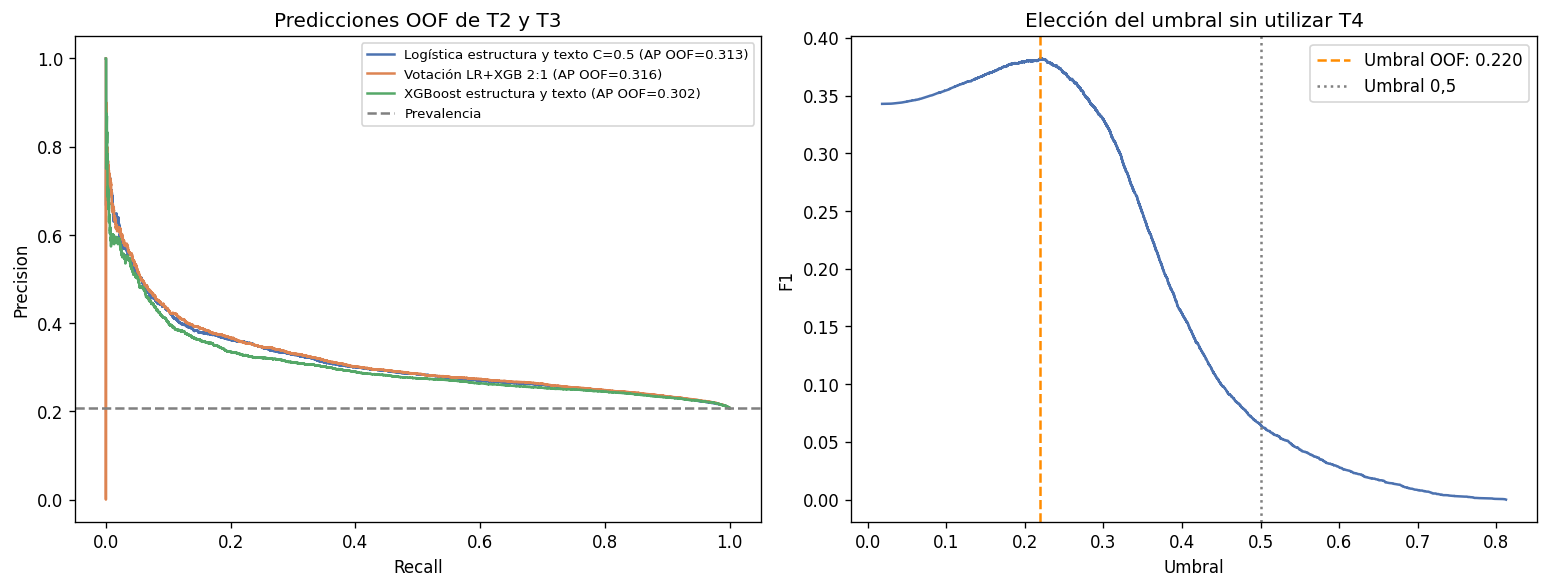

In [268]:
y_oof_seleccion = y_train.loc[mascara_oof_seleccion]
umbrales_por_modelo = {}
f1_oof_por_modelo = {}
curvas_umbrales = {}
for nombre in nombres_finalistas:
    probabilidad = predicciones_oof.loc[mascara_oof_seleccion, nombre].to_numpy()
    precisiones, recalls, umbrales = precision_recall_curve(y_oof_seleccion, probabilidad)
    f1_umbrales = np.divide(2 * precisiones[:-1] * recalls[:-1],
        precisiones[:-1] + recalls[:-1], out=np.zeros_like(umbrales),
        where=(precisiones[:-1] + recalls[:-1]) > 0)
    indices = np.flatnonzero(np.isclose(f1_umbrales, f1_umbrales.max(), rtol=0, atol=1e-12))
    mejor = indices[-1]
    umbrales_por_modelo[nombre] = float(umbrales[mejor])
    f1_oof_por_modelo[nombre] = float(f1_umbrales[mejor])
    curvas_umbrales[nombre] = (umbrales, f1_umbrales)
    print(f"{nombre}: umbral OOF={umbrales[mejor]:.6f}; F1 OOF ajustado={f1_umbrales[mejor]:.4f}")
umbral_elegido = umbrales_por_modelo[nombre_modelo_elegido]
print("Modelo y umbral fijados antes de evaluar T4:", nombre_modelo_elegido, umbral_elegido)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for nombre in nombres_finalistas:
    probabilidad = predicciones_oof.loc[mascara_oof_seleccion, nombre]
    p, r, _ = precision_recall_curve(y_oof_seleccion, probabilidad)
    ejes[0].plot(r, p, label=f"{nombre} (AP OOF={average_precision_score(y_oof_seleccion, probabilidad):.3f})")
ejes[0].axhline(y_oof_seleccion.mean(), color="gray", linestyle="--", label="Prevalencia")
ejes[0].set(xlabel="Recall", ylabel="Precision", title="Predicciones OOF de T2 y T3")
ejes[0].legend(fontsize=8)
umbrales, f1_umbrales = curvas_umbrales[nombre_modelo_elegido]
ejes[1].plot(umbrales, f1_umbrales)
ejes[1].axvline(umbral_elegido, color="darkorange", linestyle="--", label=f"Umbral OOF: {umbral_elegido:.3f}")
ejes[1].axvline(0.5, color="gray", linestyle=":", label="Umbral 0,5")
ejes[1].set(xlabel="Umbral", ylabel="F1", title="Elección del umbral sin utilizar T4")
ejes[1].legend()
plt.tight_layout()
plt.show()


Ajustando Votación LR+XGB 2:1 con 92,602 filas


,Decisión,F1,Precision,Recall,TN,FP,FN,TP
0,Siempre no desierta,0.0000,0.0000,0.0000,28697,0,7190,0
1,Siempre desierta,0.3338,0.2004,1.0000,0,28697,0,7190
2,"Logística estructura y texto C=0.5: umbral 0,5",0.0941,0.6193,0.0509,28472,225,6824,366
3,Logística estructura y texto C=0.5: umbral OOF,0.3707,0.2987,0.4885,20453,8244,3678,3512
4,"Votación LR+XGB 2:1: umbral 0,5",0.0712,0.6818,0.0376,28571,126,6920,270
5,Votación LR+XGB 2:1: umbral OOF,0.3741,0.2953,0.5103,19943,8754,3521,3669
6,"XGBoost estructura y texto: umbral 0,5",0.0550,0.6913,0.0287,28605,92,6984,206
7,XGBoost estructura y texto: umbral OOF,0.3700,0.2444,0.7618,11761,16936,1713,5477


,Modelo,AP_T4,ROC_AUC_T4
0,Logística estructura y texto C=0.5,0.3360,0.6547
1,Votación LR+XGB 2:1,0.3379,0.6567
2,XGBoost estructura y texto,0.3107,0.6298


T4 completo: 35,887 filas; F1 del elegido por CV: 0.3741


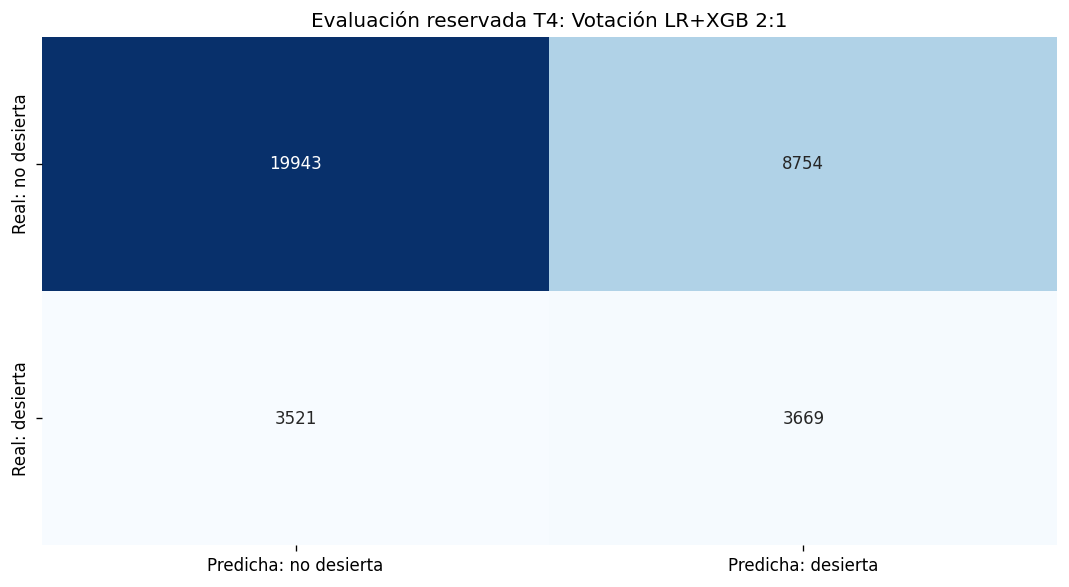

In [269]:
def ajustar_finalistas(X, y):
    ajustados = {}
    print(f"Ajustando {nombre_mejor_ensamble} con {len(X):,} filas", flush=True)
    ensamble = clone(candidatos_ensamble[nombre_mejor_ensamble])
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        ensamble.fit(X, y)
    ajustados[nombre_mejor_ensamble] = ensamble
    # Reutilizar los componentes ya ajustados, sin repetir el entrenamiento.
    for nombre, componente in zip(configuraciones_votacion[nombre_mejor_ensamble]["bases"], ensamble.estimators_):
        ajustados[nombre] = componente
    for nombre in nombres_finalistas:
        if nombre not in ajustados:
            print(f"Ajustando {nombre}", flush=True)
            modelo = clone(todos_candidatos[nombre])
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                modelo.fit(X, y)
            ajustados[nombre] = modelo
    return ajustados


def resumir_predicciones(nombre, y_real, pred):
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {"Decisión": nombre, "F1": f1_score(y_real, pred, zero_division=0),
            "Precision": precision_score(y_real, pred, zero_division=0),
            "Recall": recall_score(y_real, pred, zero_division=0),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}


modelos_evaluacion = ajustar_finalistas(x_modelos.loc[mascara_ajuste_evaluacion], y_train.loc[mascara_ajuste_evaluacion])
X_evaluacion = x_modelos.loc[mascara_evaluacion]
y_evaluacion = y_train.loc[mascara_evaluacion]
filas_evaluacion = [
    resumir_predicciones("Siempre no desierta", y_evaluacion, np.zeros(len(y_evaluacion), dtype=int)),
    resumir_predicciones("Siempre desierta", y_evaluacion, np.ones(len(y_evaluacion), dtype=int))
]
probabilidades_t4 = {}
ordenamiento_t4 = []
for nombre in nombres_finalistas:
    probabilidad = modelos_evaluacion[nombre].predict_proba(X_evaluacion)[:, 1]
    probabilidades_t4[nombre] = probabilidad
    filas_evaluacion.append(resumir_predicciones(f"{nombre}: umbral 0,5", y_evaluacion, (probabilidad >= 0.5).astype(int)))
    filas_evaluacion.append(resumir_predicciones(f"{nombre}: umbral OOF", y_evaluacion, (probabilidad >= umbrales_por_modelo[nombre]).astype(int)))
    ordenamiento_t4.append({"Modelo": nombre, "AP_T4": average_precision_score(y_evaluacion, probabilidad),
                            "ROC_AUC_T4": roc_auc_score(y_evaluacion, probabilidad)})
evaluacion_final = pd.DataFrame(filas_evaluacion)
ordenamiento_t4 = pd.DataFrame(ordenamiento_t4)
display(evaluacion_final.round(4))
display(ordenamiento_t4.round(4))
evaluacion_final.round(4).to_csv("evaluacion_t4_trimestral.csv", index=False)
p_evaluacion = probabilidades_t4[nombre_modelo_elegido]
pred_evaluacion = (p_evaluacion >= umbral_elegido).astype(int)
print(f"T4 completo: {len(y_evaluacion):,} filas; F1 del elegido por CV: {f1_score(y_evaluacion, pred_evaluacion):.4f}")
matriz_confusion_final = pd.DataFrame(confusion_matrix(y_evaluacion, pred_evaluacion, labels=[0, 1]),
    index=["Real: no desierta", "Real: desierta"], columns=["Predicha: no desierta", "Predicha: desierta"])
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(matriz_confusion_final, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title(f"Evaluación reservada T4: {nombre_modelo_elegido}")
plt.tight_layout()
plt.show()


# 6. Ajuste final y predicciones de prueba

Se reajustan el mejor individual, la mejor votación y el mejor XGBoost con las filas publicadas dentro de los cuatro trimestres de 2024 cuya etiqueta está disponible antes de la primera publicación de prueba. El filtro de madurez puede excluir publicaciones de fines de año del ajuste final, aunque **T4 completo sí se utiliza en la evaluación retrospectiva**. Se informa la cantidad excluida; no se cambia la cobertura de los trimestres.

Se conservan los umbrales OOF, sin usar los resultados de T4 para modificarlos. Se generan `submission_modelo_cv_trimestral.csv`, correspondiente a la selección global por CV, y `submission_ensamble_cv_trimestral.csv`, correspondiente al mejor ensamblaje. Si gana la votación, ambos contienen las mismas predicciones. No se dispone de etiquetas de prueba para medir el modelo final reajustado.

También se genera `submission_xgboost_cv_trimestral.csv` con el mejor XGBoost individual y su umbral OOF, independientemente de qué familia gane la comparación global. Los tres archivos cubren todos los registros de `test_df`.


In [270]:
mascara_ajuste_final = mascara_2024 & fecha_etiqueta_modelos.lt(primera_fecha_prueba)
print(f"Ajuste final: {mascara_ajuste_final.sum():,} filas; excluidas por disponibilidad o cierre: {(mascara_2024 & ~mascara_ajuste_final).sum():,}", flush=True)
modelos_finales = ajustar_finalistas(x_modelos.loc[mascara_ajuste_final], y_train.loc[mascara_ajuste_final])
probabilidades_prueba_por_modelo = {
    nombre: modelos_finales[nombre].predict_proba(x_prueba_modelos)[:, 1]
    for nombre in nombres_finalistas
}
if test_df["id"].duplicated().any() or sample_submission_df["id"].duplicated().any():
    raise ValueError("Identificadores duplicados en prueba o plantilla")
if set(test_df["id"]) != set(sample_submission_df["id"]):
    raise ValueError("Los identificadores de prueba no coinciden con la plantilla")


def crear_submission_cv(nombre):
    pred = (probabilidades_prueba_por_modelo[nombre] >= umbrales_por_modelo[nombre]).astype(int)
    por_id = pd.DataFrame({"id": test_df["id"], TARGET: pred})
    submission = sample_submission_df[["id"]].merge(por_id, on="id", how="left", sort=False, validate="one_to_one")
    assert submission["id"].equals(sample_submission_df["id"])
    assert submission[TARGET].isin([0, 1]).all()
    return submission


submission_modelo_cv = crear_submission_cv(nombre_modelo_elegido)
submission_ensamble_cv = crear_submission_cv(nombre_mejor_ensamble)
submission_xgboost_cv = crear_submission_cv(nombre_mejor_xgboost)
submission_modelo_cv.to_csv("submission_modelo_cv_trimestral.csv", index=False)
submission_ensamble_cv.to_csv("submission_ensamble_cv_trimestral.csv", index=False)
submission_xgboost_cv.to_csv("submission_xgboost_cv_trimestral.csv", index=False)
modelo_final = modelos_finales[nombre_modelo_elegido]
print("Selección por CV:", nombre_modelo_elegido, "| Umbral OOF:", umbral_elegido)
print("Ensamblaje evaluado y aplicado:", nombre_mejor_ensamble)
print("Predicciones completas por archivo:", len(submission_modelo_cv))
display(submission_modelo_cv.head())

print("CSV XGBoost individual: submission_xgboost_cv_trimestral.csv | Modelo:", nombre_mejor_xgboost)


Ajuste final: 131,427 filas; excluidas por disponibilidad o cierre: 21,126
Ajustando Votación LR+XGB 2:1 con 131,427 filas
Selección por CV: Votación LR+XGB 2:1 | Umbral OOF: 0.21961649502577066
Ensamblaje evaluado y aplicado: Votación LR+XGB 2:1
Predicciones completas por archivo: 21829


,id,y_desierta
0,47254358932,0
1,295671198916,0
2,214756376398,0
3,404842360472,0
4,899379189128,1


CSV XGBoost individual: submission_xgboost_cv_trimestral.csv | Modelo: XGBoost estructura y texto


### Comparación y decisión con XGBoost

La configuración elegida entre las probadas por la misma CV trimestral es **Votación LR+XGB 2:1**, con AP media **0.3207** y desviación **0.0067**. Su umbral OOF es **0.219616**.

El mejor XGBoost individual es **XGBoost estructura y texto**, con AP media **0.3034**. La mejor votación es **Votación LR+XGB 2:1**, con AP media **0.3207**. Estos resultados corresponden a las configuraciones y ventanas comparadas; no establecen una superioridad general de un algoritmo.

En los **35,887** casos de T4 completo, el modelo elegido por CV obtiene F1 **0.3741** y el mejor XGBoost individual F1 **0.3700**, cada uno con su umbral OOF fijado previamente. T4 ya fue consultado en las iteraciones anteriores: se interpreta como evaluación temporal reutilizada, manteniéndolo fuera de la selección de configuraciones y umbrales.

El ajuste final usa **131,427** etiquetas admisibles y genera **21,829** predicciones por archivo. El resultado global está en `submission_modelo_cv_trimestral.csv`; el resultado específico de XGBoost está en `submission_xgboost_cv_trimestral.csv`. Las métricas de T4 corresponden al ajuste previo al reajuste final y no miden el desempeño etiquetado de 2025.

La evaluación anterior de **Votación suave 4:1:1** obtuvo AP media de CV **0.3187** y F1 en T4 **0.3781**. Por tanto, la incorporación de XGBoost mejora ligeramente la AP de selección, pero no mejora F1 de T4 frente a esa referencia. La elección por AP de CV se mantiene y esta diferencia se informa sin ajustar nuevamente el modelo sobre T4.

Las predicciones del ensamblaje anterior se conservan en `submission_ensamble_rf_boosting_cv.csv`.
